# Gráficas del Lab 9 (Visualización estática)
Gráficas de la infografía del Lab 9 (Visualización estática), una imagen por gráfica y con fondo blanco.
Datos: Base de Migración 2009–jun 2026 (uso académico) + resultados del Laboratorio 1 (CC3084).
Entradas (las genera calcular_datos.py a partir del repo del Lab 1):
    tot.csv         serie mensual Total (suma de Viajero)
    prophet_fc.csv  pronóstico de Prophet en el conjunto de prueba (yhat, lo, hi al 80%)
Uso:  python graficas_lab9.py [carpeta_de_salida]
Salida: g1_linea_tiempo.png, g2_estacionalidad.png, g3_cuadrante.png, g4_modelos.png, g5_proyeccion.png

In [1]:
%matplotlib inline

## Configuración

In [2]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import font_manager as fm
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle

try:
    HERE = Path(__file__).resolve().parent
except NameError:                      # dentro de un notebook
    HERE = Path.cwd()
OUT = Path(sys.argv[1]) if len(sys.argv) > 1 and not sys.argv[1].startswith("-") else HERE / "graficas"
OUT.mkdir(parents=True, exist_ok=True)

# Fuente Inter si está instalada; si no, la que trae matplotlib
try:
    for f in ["Regular", "Medium", "SemiBold", "Bold", "ExtraBold"]:
        fm.fontManager.addfont(f"/usr/share/fonts/opentype/inter/Inter-{f}.otf")
    mpl.rcParams["font.family"] = "Inter"
except Exception:
    mpl.rcParams["font.family"] = "DejaVu Sans"
mpl.rcParams["axes.unicode_minus"] = True

# Paleta: 2 temáticos (azul y gris) + 1 acento (naranja), complementarios en el círculo cromático
AZUL = "#1F3A5F"       # datos observados y titulares
AZUL_M = "#8FA7C4"     # mismo azul, tono claro
AZUL_C = "#EAF0F7"
GRIS = "#6B7280"       # contexto, ejes
GRIS_T = "#4B5563"     # texto secundario
GRID = "#E5E7EB"
NARANJA = "#C4571A"    # acento: picos, anomalías, ganador, estimación
NARANJA_C = "#E9B08B"
NARANJA_T = "#A8470F"  # mismo naranja, más oscuro, para texto pequeño
INK = "#1B1B1B"
BANDA = "#E6E2D8"      # franja de la pandemia

DPI = 300


def lienzo(w, h):
    fig = plt.figure(figsize=(w, h), facecolor="white")
    return fig


def estilo(ax, grid_y=True, size=11):
    ax.set_facecolor("white")
    for s in ["top", "right", "left"]:
        ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color(GRIS)
    ax.tick_params(axis="both", colors=GRIS_T, labelsize=size, length=0)
    if grid_y:
        ax.grid(axis="y", color=GRID, lw=0.8)
        ax.set_axisbelow(True)


def titulo(fig, texto, sub=None):
    fig.text(0.012, 0.985, texto, fontsize=12.5, fontweight="bold", color=AZUL, va="top", ha="left")
    if sub:
        fig.text(0.012, 0.985 - 0.075, sub, fontsize=10, color=GRIS_T, va="top", ha="left")


def guardar(fig, nombre):
    fig.savefig(OUT / nombre, dpi=DPI, facecolor="white")
    plt.show()
    plt.close(fig)
    print("ok", nombre)


MILES = ["0", "100 mil", "200 mil", "300 mil", "400 mil", "500 mil"]

## Datos

In [3]:
tot = pd.read_csv(HERE / "tot.csv", index_col=0, parse_dates=True).iloc[:, 0]
fc = pd.read_csv(HERE / "prophet_fc.csv", index_col=0, parse_dates=True)
te = tot.loc[fc.index]
tr = tot.loc[:fc.index[0] - pd.offsets.MonthBegin(1)]
pico_fecha, pico_val = tot.idxmax(), tot.max()
min_fecha, min_val = tot.idxmin(), tot.min()

## Gráfica 1: línea de tiempo 2009–2026 con anotaciones

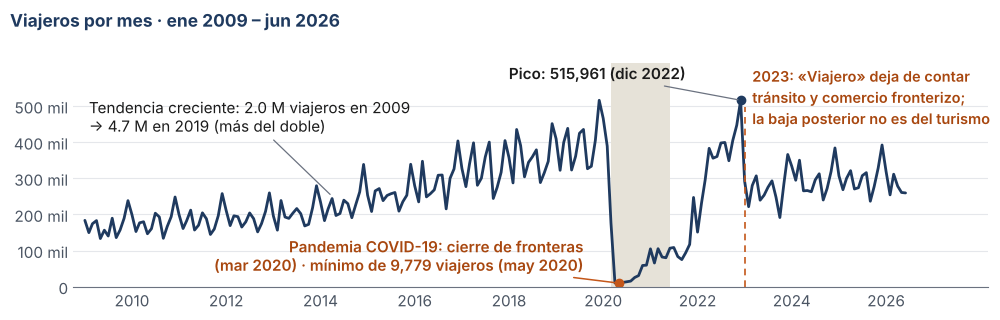

ok g1_linea_tiempo.png


In [4]:
fig = lienzo(10, 3.2)
titulo(fig, "Viajeros por mes · ene 2009 – jun 2026")
ax = fig.add_axes([0.075, 0.12, 0.915, 0.70])
estilo(ax)
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-06-01"), color=BANDA, lw=0)
ax.plot(tot.index, tot.values, color=AZUL, lw=2.0, solid_capstyle="round")
ax.set_xlim(pd.Timestamp("2008-10-01"), pd.Timestamp("2028-03-01"))
ax.set_ylim(0, 620_000)
ax.set_yticks(range(0, 600_000, 100_000)); ax.set_yticklabels(MILES)
ax.set_xticks([pd.Timestamp(f"{y}-01-01") for y in range(2010, 2027, 2)])
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.annotate("Tendencia creciente: 2.0 M viajeros en 2009\n→ 4.7 M en 2019 (más del doble)",
            xy=(pd.Timestamp("2014-04-01"), 250_000), xytext=(pd.Timestamp("2009-02-01"), 470_000),
            fontsize=11, color=INK, va="center",
            arrowprops=dict(arrowstyle="-", color=GRIS, lw=0.9))
ax.annotate("Pandemia COVID-19: cierre de fronteras\n(mar 2020) · mínimo de 9,779 viajeros (may 2020)",
            xy=(min_fecha, min_val), xytext=(pd.Timestamp("2019-08-01"), 85_000),
            fontsize=11, color=NARANJA_T, fontweight="semibold", va="center", ha="right",
            arrowprops=dict(arrowstyle="-", color=NARANJA, lw=1.1))
ax.plot([min_fecha], [min_val], "o", color=NARANJA, ms=6)
ax.annotate("Pico: 515,961 (dic 2022)", xy=(pico_fecha, pico_val),
            xytext=(pd.Timestamp("2021-10-01"), 590_000), fontsize=11, color=INK,
            fontweight="semibold", va="center", ha="right",
            arrowprops=dict(arrowstyle="-", color=GRIS, lw=0.9))
ax.plot([pico_fecha], [pico_val], "o", color=AZUL, ms=6)
ax.axvline(pd.Timestamp("2023-01-01"), ymax=0.80, color=NARANJA, lw=1.2, ls=(0, (4, 3)))
ax.text(pd.Timestamp("2023-03-01"), 520_000,
        "2023: «Viajero» deja de contar\ntránsito y comercio fronterizo;\nla baja posterior no es del turismo",
        fontsize=10.5, color=NARANJA_T, fontweight="semibold", va="center", ha="left", linespacing=1.2)
guardar(fig, "g1_linea_tiempo.png")

## Gráfica 2: estacionalidad (año × mes) con Semana Santa, Bono 14 y Aguinaldo

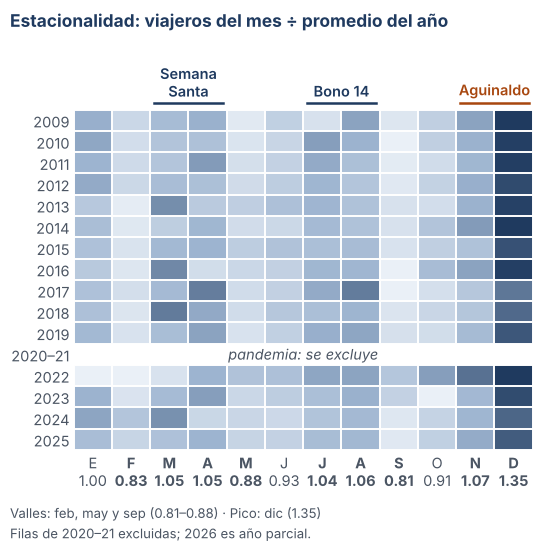

ok g2_estacionalidad.png


In [5]:
MESES = ["E", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]
buenos = [y for y in range(2009, 2026) if y not in (2020, 2021)]
d = tot[tot.index.year.isin(buenos)]
mat = d.groupby([d.index.year, d.index.month]).sum().unstack()
mat = mat.div(mat.mean(axis=1), axis=0)          # viajeros del mes ÷ promedio mensual de ese año
prom = mat.mean()
filas = list(range(2009, 2020)) + ["2020–21"] + list(range(2022, 2026))
grid = np.full((len(filas), 12), np.nan)
for i, y in enumerate(filas):
    if y in mat.index:
        grid[i] = mat.loc[y].values

fig = lienzo(5.4, 5.5)
titulo(fig, "Estacionalidad: viajeros del mes ÷ promedio del año")
ax = fig.add_axes([0.13, 0.185, 0.85, 0.70])
cmap = LinearSegmentedColormap.from_list("az", [AZUL_C, "#9DB4D0", AZUL])   # un solo tono, claro → oscuro
ax.imshow(np.ma.masked_invalid(grid), cmap=cmap, vmin=0.75, vmax=1.4, aspect="auto", interpolation="nearest")
ax.set_xticks(np.arange(12))
ax.set_xticklabels([f"{m}\n{prom.iloc[i]:.2f}" for i, m in enumerate(MESES)])
for i, lab in enumerate(ax.get_xticklabels()):
    v = prom.iloc[i]
    lab.set_color(NARANJA_T if i == 11 else (AZUL if v >= 1.04 else GRIS_T))
    lab.set_fontweight("bold" if (v >= 1.04 or v <= 0.88) else "regular")
ax.set_yticks(range(len(filas))); ax.set_yticklabels([str(y) for y in filas])
ax.tick_params(length=0, labelsize=10.5, colors=GRIS_T, pad=3)
for s in ax.spines.values():
    s.set_visible(False)
ax.text(5.5, filas.index("2020–21"), "pandemia: se excluye", ha="center", va="center", fontsize=10.5, color=GRIS_T, style="italic")
ax.set_xticks(np.arange(-0.5, 12, 1), minor=True); ax.set_yticks(np.arange(-0.5, len(filas), 1), minor=True)
ax.grid(which="minor", color="white", lw=1.4); ax.tick_params(which="minor", length=0)
ax.set_ylim(len(filas) - 0.5, -2.6)
for (x0, x1, txt, col) in [(2, 3, "Semana\nSanta", AZUL), (6, 7, "Bono 14", AZUL), (10, 11, "Aguinaldo", NARANJA_T)]:
    ax.plot([x0 - 0.4, x1 + 0.4], [-0.8, -0.8], color=col, lw=1.8, clip_on=False)
    ax.text((x0 + x1) / 2, -0.95, txt, ha="center", va="bottom", fontsize=10.5, fontweight="semibold",
            color=col, linespacing=1.0)
fig.text(0.012, 0.05, "Valles: feb, may y sep (0.81–0.88) · Pico: dic (1.35)\nFilas de 2020–21 excluidas; 2026 es año parcial.",
         fontsize=9.5, color=GRIS_T, va="center", ha="left", linespacing=1.3)
guardar(fig, "g2_estacionalidad.png")

## Gráfica 3: cuadrante comparativo (qué serie lidera en cada categoría)

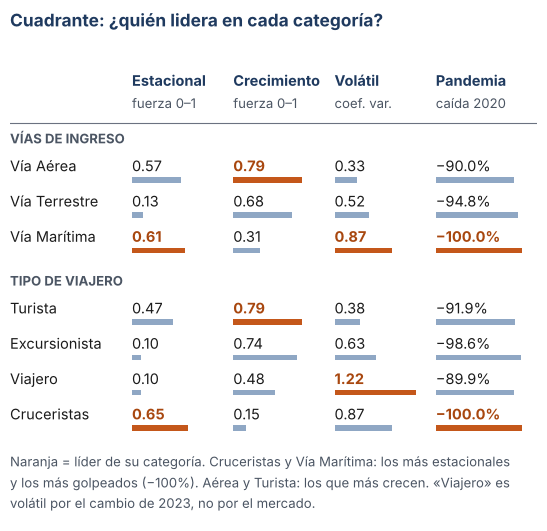

ok g3_cuadrante.png


In [6]:
datos = {
    "VÍAS DE INGRESO": [("Vía Aérea", 0.57, 0.79, 0.33, -90.0), ("Vía Terrestre", 0.13, 0.68, 0.52, -94.8),
                        ("Vía Marítima", 0.61, 0.31, 0.87, -100.0)],
    "TIPO DE VIAJERO": [("Turista", 0.47, 0.79, 0.38, -91.9), ("Excursionista", 0.10, 0.74, 0.63, -98.6),
                        ("Viajero", 0.10, 0.48, 1.22, -89.9), ("Cruceristas", 0.65, 0.15, 0.87, -100.0)],
}
cols = [("Estacional", "fuerza 0–1", 1.0, False), ("Crecimiento", "fuerza 0–1", 1.0, False),
        ("Volátil", "coef. var.", 1.3, False), ("Pandemia", "caída 2020", 100.0, True)]
fig = lienzo(5.4, 5.3)
titulo(fig, "Cuadrante: ¿quién lidera en cada categoría?")
ax = fig.add_axes([0.012, 0.02, 0.976, 0.87]); ax.axis("off")
ax.set_xlim(0, 5.4); ax.set_ylim(4.7, 0)
lab_w, cw = 1.25, (5.4 - 1.25) / 4
for j, (c1, c2, _, _) in enumerate(cols):
    x = lab_w + j * cw
    ax.text(x, 0.12, c1, fontsize=10.5, fontweight="bold", color=AZUL, va="top")
    ax.text(x, 0.36, c2, fontsize=9.5, color=GRIS_T, va="top")
ax.plot([0, 5.4], [0.64, 0.64], color=GRIS, lw=0.8)
y = 0.72
for grupo, filas_g in datos.items():
    ax.text(0, y, grupo, fontsize=9.5, fontweight="bold", color=GRIS_T, va="top")
    y += 0.27
    arr = np.array([[r[1], r[2], r[3], abs(r[4])] for r in filas_g])
    gana = arr.argmax(axis=0)
    for i, r in enumerate(filas_g):
        ax.text(0, y, r[0], fontsize=10.5, color=INK, va="top")
        for j in range(4):
            x = lab_w + j * cw
            v = arr[i, j]
            es = gana[j] == i
            ax.text(x, y, (f"−{v:.1f}%" if cols[j][3] else f"{v:.2f}"), fontsize=10.5, va="top",
                    fontweight="bold" if es else "regular", color=NARANJA_T if es else INK)
            ax.add_patch(Rectangle((x, y + 0.205), (cw - 0.15) * v / cols[j][2], 0.055,
                                   facecolor=NARANJA if es else AZUL_M, edgecolor="none"))
        y += 0.36
    y += 0.1
ax.text(0, y + 0.02,
        "Naranja = líder de su categoría. Cruceristas y Vía Marítima: los más estacionales\n"
        "y los más golpeados (−100%). Aérea y Turista: los que más crecen. «Viajero» es\n"
        "volátil por el cambio de 2023, no por el mercado.", fontsize=9.5, color=GRIS_T, va="top", linespacing=1.3)
guardar(fig, "g3_cuadrante.png")

## Gráfica 4: comparación de modelos (MAE y RMSE en el conjunto de prueba)

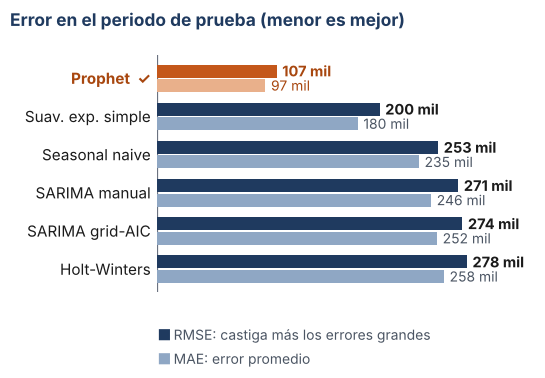

ok g4_modelos.png


In [7]:
modelos = [("Prophet", 97185, 107269), ("Suav. exp. simple", 180234, 199919), ("Seasonal naive", 235305, 252543),
           ("SARIMA manual", 246270, 270639), ("SARIMA grid-AIC", 251561, 274308), ("Holt-Winters", 257791, 278371)]
fig = lienzo(5.4, 3.7)
titulo(fig, "Error en el periodo de prueba (menor es mejor)")
ax = fig.add_axes([0.285, 0.22, 0.70, 0.64])
estilo(ax, grid_y=False); ax.spines["bottom"].set_visible(False)
ax.set_xticks([]); ax.set_yticks([])
n = len(modelos)
for i, (nm, mae, rmse) in enumerate(modelos):
    yb = n - 1 - i
    gana = i == 0
    ax.barh(yb + 0.19, rmse, height=0.34, color=NARANJA if gana else AZUL, zorder=3)
    ax.barh(yb - 0.19, mae, height=0.34, color=NARANJA_C if gana else AZUL_M, zorder=3)
    ax.text(rmse + 5000, yb + 0.19, f"{rmse/1000:,.0f} mil", va="center", fontsize=10.5, fontweight="bold",
            color=NARANJA_T if gana else INK)
    ax.text(mae + 5000, yb - 0.19, f"{mae/1000:,.0f} mil", va="center", fontsize=10, color=NARANJA_T if gana else GRIS_T)
    ax.text(-6000, yb, nm + ("  ✓" if gana else ""), ha="right", va="center", fontsize=11,
            fontweight="bold" if gana else "regular", color=NARANJA_T if gana else INK)
ax.axvline(0, color=GRIS, lw=0.9)
ax.set_xlim(0, 340_000); ax.set_ylim(-0.6, n - 0.4)
fig.text(0.285, 0.105, "■", fontsize=11, color=AZUL, va="center"); fig.text(0.315, 0.105, "RMSE: castiga más los errores grandes", fontsize=10, color=GRIS_T, va="center")
fig.text(0.285, 0.04, "■", fontsize=11, color=AZUL_M, va="center"); fig.text(0.315, 0.04, "MAE: error promedio", fontsize=10, color=GRIS_T, va="center")
guardar(fig, "g4_modelos.png")

## Gráfica 5: proyección del modelo ganador (Prophet) con intervalo de confianza 80% rotulado «Estimación»

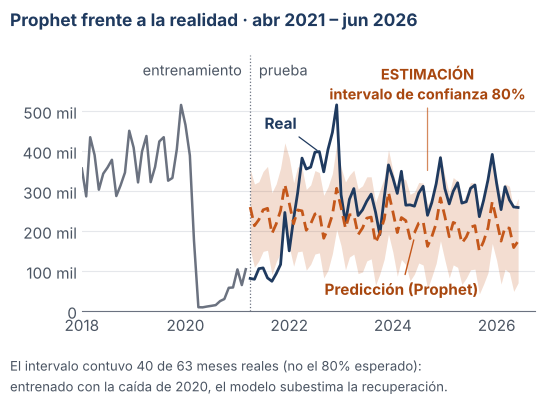

ok g5_proyeccion.png


In [8]:
fig = lienzo(5.4, 4.0)
titulo(fig, "Prophet frente a la realidad · abr 2021 – jun 2026")
ax = fig.add_axes([0.145, 0.23, 0.84, 0.64])
estilo(ax)
hist = tr["2018-01-01":]
ax.plot(hist.index, hist.values, color=GRIS, lw=1.8)
ax.fill_between(fc.index, fc.lo, fc.hi, color=NARANJA, alpha=0.20, lw=0, zorder=2)
ax.plot(te.index, te.values, color=AZUL, lw=2.0, zorder=4)
ax.plot(fc.index, fc.yhat, color=NARANJA, lw=2.0, ls=(0, (4, 2.2)), zorder=5)
ax.set_xlim(pd.Timestamp("2018-01-01"), pd.Timestamp("2026-10-01")); ax.set_ylim(0, 640_000)
ax.set_yticks(range(0, 600_000, 100_000)); ax.set_yticklabels(MILES)
ax.xaxis.set_major_locator(mdates.YearLocator(2)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.axvline(pd.Timestamp("2021-04-01"), color=GRIS, lw=0.9, ls=":")
ax.text(pd.Timestamp("2021-02-01"), 625_000, "entrenamiento", ha="right", fontsize=10.5, color=GRIS_T, va="top")
ax.text(pd.Timestamp("2021-06-01"), 625_000, "prueba", ha="left", fontsize=10.5, color=GRIS_T, va="top")
ax.annotate("Real", xy=(pd.Timestamp("2022-08-01"), 398_000), xytext=(pd.Timestamp("2021-11-01"), 470_000),
            fontsize=11, color=AZUL, fontweight="bold", ha="center", va="center",
            arrowprops=dict(arrowstyle="-", color=AZUL, lw=0.9))
ax.annotate("Predicción (Prophet)", xy=(pd.Timestamp("2024-06-01"), 185_000), xytext=(pd.Timestamp("2024-03-01"), 55_000),
            fontsize=11, color=NARANJA_T, fontweight="bold", ha="center", va="center",
            arrowprops=dict(arrowstyle="-", color=NARANJA, lw=1.0))
ax.text(pd.Timestamp("2024-09-01"), 570_000, "ESTIMACIÓN\nintervalo de confianza 80%", fontsize=10.5, color=NARANJA_T,
        fontweight="bold", ha="center", va="center", linespacing=1.2)
ax.annotate("", xy=(pd.Timestamp("2024-09-01"), 345_000), xytext=(pd.Timestamp("2024-09-01"), 515_000),
            arrowprops=dict(arrowstyle="-", color=NARANJA, lw=0.9, alpha=0.7))
dentro = int(((te >= fc.lo) & (te <= fc.hi)).sum())
fig.text(0.012, 0.065, f"El intervalo contuvo {dentro} de {len(te)} meses reales (no el 80% esperado):\n"
         "entrenado con la caída de 2020, el modelo subestima la recuperación.",
         fontsize=9.5, color=GRIS_T, va="center", ha="left", linespacing=1.3)
guardar(fig, "g5_proyeccion.png")